# Q-Learning: Off-Policy Control on a Slippery Lake

**Family:** Reinforcement learning | **Level:** Intermediate | **Dataset:** `FrozenLake-v1` | **Runs on:** CPU, about 2 minute(s)

Learn the optimal action values while behaving exploratively.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- The Q-learning update and the max operator
- Why Q-learning is off policy
- Exploration schedules
- How to compare a learned policy with the DP optimum

**Prerequisites:**

- Probability basics
- Markov decision processes

**Skills you will have afterwards:**

- Run several seeds
- Report learning curves with spread
- Compare with a baseline policy

## 2. Real-World Problem

**Context.** The agent does not know the ice model, but can try crossing many times.

**The problem.** Learn to cross the slippery 4 by 4 lake from interaction only.

**Why it matters.** The exact optimum from DP is known, so we can measure how close learning gets.

**Why machine learning.** The model is unknown to the learner.

**Why this algorithm.** Q-learning is the basic model free control method.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### Q-learning

- **Type:** foundational paper
- **Authors:** Watkins, C. J. C. H. and Dayan, P.
- **Year and venue:** 1992, Machine Learning 8(3-4):279-292
- **DOI or URL:** https://doi.org/10.1007/BF00992698
- **Verification:** Crossref 2026-11-17
- **Research objective:** Prove convergence of Q-learning.
- **Methodology:** Off policy update towards the maximum action value of the next state.
- **Dataset:** Theory.
- **Main findings:** Converges to the optimal action values when all pairs are visited often enough.
- **Limitations:** Tabular, needs decaying learning rates.

### Gymnasium: A Standard Interface for Reinforcement Learning Environments

- **Type:** benchmark paper
- **Authors:** Towers, M. et al.
- **Year and venue:** 2024, arXiv:2407.17032
- **DOI or URL:** https://arxiv.org/abs/2407.17032
- **Verification:** arXiv abstract page 2026-11-17
- **Research objective:** Describe the Gymnasium API.
- **Methodology:** Software paper.
- **Dataset:** Not applicable.
- **Main findings:** Standard reset and step interface.
- **Limitations:** Software description.

**Relationship to this notebook.** Watkins and Dayan prove convergence of Q-learning for tabular problems. We check how close a finite run gets. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Update.** $Q(S,A) \leftarrow Q(S,A) + \alpha\,[R + \gamma \max_{a'} Q(S',a') - Q(S,A)]$.

**Off policy.** The target uses the greedy action in $S'$, whatever action the behaviour policy takes next. Q converges to $Q^*$ if every pair is visited infinitely often and step sizes decrease suitably.

**Exploration.** Epsilon greedy with decaying epsilon.

**Limits.** Maximisation bias, slow with sparse rewards.

## 5. Dataset Introduction

**FrozenLake-v1** 4 by 4 slippery, as in the DP notebook. The reward is sparse (1 only at the goal). Dynamic programming gave the optimal success probability, which is the reference.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from IPython.display import display

from ml_lab.rl import tabular, deep
from ml_lab.evaluation import evaluate_policy
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "q_learning"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()
print("gymnasium", gym.__version__)

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0
gymnasium 1.4.0


## 6. Exploratory Data Analysis

There is no dataset. We inspect the environment: observation and action spaces, rewards and a random policy baseline. 

In [2]:
P, nS, nA = tabular.transition_model("FrozenLake-v1", is_slippery=True)
V_opt, pol_opt, _ = tabular.value_iteration(P, nS, nA, 0.99)
exact_opt, _ = tabular.policy_evaluation(P, pol_opt, nS, gamma=1.0)
print("optimal success probability from dynamic programming:", round(float(exact_opt[0]), 4))

optimal success probability from dynamic programming: 0.8235


## 7. Data Preprocessing

Step size 0.1, discount 0.99, epsilon decays from 1.0 with factor 0.9995 per episode (floor 0.01). Training 20 000 episodes, 5 seeds. Evaluation: greedy policy for 2000 episodes with seeds not used in training.

In [3]:
EPISODES = 20000
KW = dict(alpha=0.1, gamma=0.99, epsilon=1.0, decay=0.9995, is_slippery=True)

## 8. Algorithm Implementation

### 8.1 Concept

Each step moves the value of the chosen action toward the reward plus the best value available next. Over many tries the best actions stand out.

### 8.2 Python implementation from scratch

Source of the update:

In [4]:
print(inspect.getsource(tabular.q_learning))

def q_learning(env_id, episodes, alpha=0.5, gamma=0.99, epsilon=0.1, seed=0, decay=None, **env_kwargs):
    """Off policy TD control. Returns Q and the return of every episode."""
    env = gym.make(env_id, **env_kwargs)
    rng = np.random.default_rng(seed)
    q = np.zeros((env.observation_space.n, env.action_space.n))
    returns = []
    state, _ = env.reset(seed=seed)
    for ep in range(episodes):
        eps = epsilon if decay is None else max(0.01, epsilon * decay ** ep)
        state, _ = env.reset()
        done, total = False, 0.0
        while not done:
            action = epsilon_greedy(q[state], eps, rng)
            nxt, reward, term, trunc, _ = env.step(action)
            target = reward + gamma * q[nxt].max() * (not term)
            q[state, action] += alpha * (target - q[state, action])
            state, total, done = nxt, total + reward, term or trunc
        returns.append(total)
    env.close()
    return q, np.array(returns)



### 8.3 Library implementation

The algorithm is implemented in `src/ml_lab/rl` without an RL library. Gymnasium supplies only the environment.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `alpha` | Step size. |
| `gamma` | Discount. |
| `epsilon`, `decay` | Exploration schedule. |

## 9. Model Training

Train 5 seeds. After training we evaluate each greedy policy.

In [5]:
runs = [tabular.q_learning("FrozenLake-v1", EPISODES, seed=s, **KW) for s in range(5)]
for s, (q, ret) in enumerate(runs):
    print("seed", s, "| training success rate over last 2000 episodes (with exploration):", round(float(ret[-2000:].mean()), 3))

seed 0 | training success rate over last 2000 episodes (with exploration): 0.688
seed 1 | training success rate over last 2000 episodes (with exploration): 0.659
seed 2 | training success rate over last 2000 episodes (with exploration): 0.7
seed 3 | training success rate over last 2000 episodes (with exploration): 0.701
seed 4 | training success rate over last 2000 episodes (with exploration): 0.67


## 10. Evaluation

Greedy success rate over 2000 evaluation episodes for each seed, compared with the simulated success rate of the DP optimal policy (same episodes) and a random policy.

In [6]:
def success_of(policy_fn, episodes=2000, seed0=50000):
    env = gym.make("FrozenLake-v1", is_slippery=True); wins = 0
    for i in range(episodes):
        s, _ = env.reset(seed=seed0 + i); done = False
        while not done:
            s, r, term, trunc, _ = env.step(policy_fn(s)); done = term or trunc
        wins += r > 0
    return wins / episodes
learned = np.array([success_of(lambda s, q=q: int(q[s].argmax())) for q, _ in runs])
dp_success = success_of(lambda s: int(pol_opt[s]))
rng_eval = np.random.default_rng(0)
random_success = success_of(lambda s: int(rng_eval.integers(4)))
display(pd.DataFrame({"success_rate": list(learned) + [dp_success, random_success]}, index=[f"Q-learning seed {i}" for i in range(5)] + ["DP optimal policy", "random policy"]).round(4))
METRICS = {"success_rate_mean": float(learned.mean()), "success_rate_std": float(learned.std(ddof=1)), "dp_optimal_success_simulated": float(dp_success),
           "dp_optimal_success_exact": float(exact_opt[0]), "random_success": float(random_success)}
CONFIG = {**{k: v for k, v in KW.items() if k != "is_slippery"}, "episodes": EPISODES, "seeds": 5}
EXTRA = {"per_seed_success": [float(x) for x in learned]}

record = ExperimentRecord(notebook=NOTEBOOK_ID, family="reinforcement_learning", algorithm="QLearning", dataset="FrozenLake-v1",
                          task="control", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

,success_rate
Q-learning seed 0,0.7495
Q-learning seed 1,0.7495
Q-learning seed 2,0.7495
Q-learning seed 3,0.7495
Q-learning seed 4,0.7495
DP optimal policy,0.7495
random policy,0.0180


saved: experiments/results/q_learning.json


,metric
success_rate_mean,0.7495
success_rate_std,0.0000
dp_optimal_success_simulated,0.7495
dp_optimal_success_exact,0.8235
random_success,0.0180


## 11. Visualization

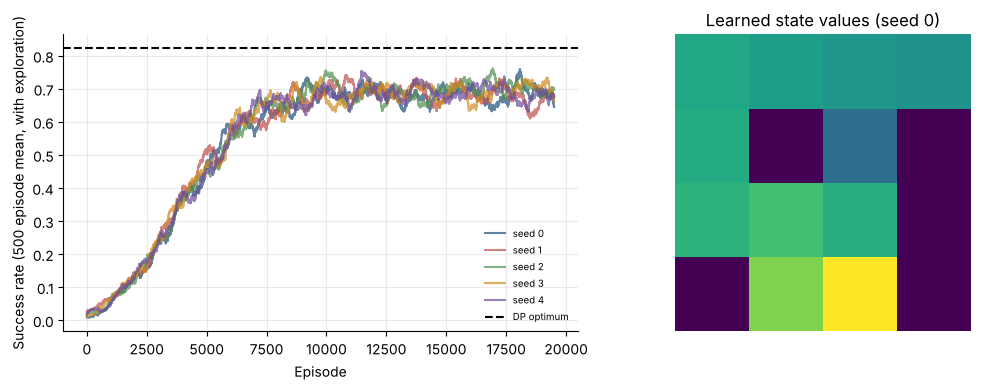

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for s, (q, ret) in enumerate(runs):
    axes[0].plot(np.convolve(ret, np.ones(500) / 500, mode="valid"), alpha=0.7, label=f"seed {s}")
axes[0].axhline(float(exact_opt[0]), color="black", linestyle="--", label="DP optimum"); axes[0].set_xlabel("Episode"); axes[0].set_ylabel("Success rate (500 episode mean, with exploration)"); axes[0].legend(fontsize=7)
axes[1].imshow(runs[0][0].max(axis=1).reshape(4, 4), cmap="viridis"); axes[1].set_title("Learned state values (seed 0)"); axes[1].axis("off")
plt.tight_layout(); save_figure(fig, NOTEBOOK_ID, "curves"); plt.show()

## 12. Interpretation

Compare the learned policy with the DP policy state by state.

In [8]:
agree = [float(np.mean(q.argmax(axis=1) == pol_opt)) for q, _ in runs]
print("share of states where the learned action equals the DP action, by seed:", np.round(agree, 2))
print("states never updated (all zero row):", [int((q.max(axis=1) == 0).sum()) for q, _ in runs])

share of states where the learned action equals the DP action, by seed: [1.   0.94 0.94 1.   0.94]
states never updated (all zero row): [5, 5, 5, 5, 5]


## 13. Experiments and Challenges

### Experiment 1: Step size

Alpha 0.02, 0.1, 0.5, 3 seeds, greedy success rate.

In [9]:
for a in [0.02, 0.1, 0.5]:
    res = [success_of(lambda s, q=q: int(q[s].argmax()), 1000) for q, _ in [tabular.q_learning("FrozenLake-v1", EPISODES, seed=s, **{**KW, "alpha": a}) for s in range(3)]]
    print(f"alpha={a}: success {np.mean(res):.3f}")

alpha=0.02: success 0.748


alpha=0.1: success 0.761


alpha=0.5: success 0.759


### Experiment 2: Exploration schedule

Constant epsilon 0.1 versus decaying epsilon.

In [10]:
for name, kw in [("constant 0.1", dict(epsilon=0.1, decay=None)), ("decaying", dict(epsilon=1.0, decay=0.9995))]:
    res = [success_of(lambda s, q=q: int(q[s].argmax()), 1000) for q, _ in [tabular.q_learning("FrozenLake-v1", EPISODES, seed=s, **{**KW, **kw}) for s in range(3)]]
    print(f"{name}: success {np.mean(res):.3f}")

constant 0.1: success 0.759


decaying: success 0.761


### Experiment 3: Amount of training

Success against the number of episodes.

In [11]:
for n in [1000, 5000, 20000]:
    res = [success_of(lambda s, q=q: int(q[s].argmax()), 1000) for q, _ in [tabular.q_learning("FrozenLake-v1", n, seed=s, **{**KW, "decay": 0.9995 if n >= 20000 else 0.999}) for s in range(3)]]
    print(f"{n} episodes: success {np.mean(res):.3f}")

1000 episodes: success 0.636


5000 episodes: success 0.756


20000 episodes: success 0.761


### Exercises for learners

1. Repeat with a different set of seeds and report the spread.
2. Change the discount factor and describe what happens to the learned behaviour.
3. Change one hyperparameter by a factor of 10 and compare learning curves.

## 14. Research Discussion

Watkins and Dayan prove convergence in the limit. Our runs are finite, so the gap to the DP optimum and the spread across seeds show how far a practical run gets.

**Dataset and method differences.** The papers above use other data and protocols. We do not claim that our numbers agree or disagree with them. This notebook only shows whether the behaviour they describe appears on our data.

**Possible improvements.** Double Q-learning, optimistic initial values, and more seeds with confidence intervals.

**Research limitations.** One dataset and one seed for the headline numbers. Few seeds (see the notebook), small environments, and no hyperparameter search beyond the experiments shown.

## 15. Summary and Further Reading

**Key takeaways**

- Q-learning learns Q* off policy.
- Compare with DP when the model is small.
- Seeds matter.

**Use cases.** Small discrete control tasks.

**Limitations.** Tabular, maximisation bias.

**Recommended next notebook.** Deep Q-Networks.

**Further reading.** See `references.md` in this folder.